# 46. 변화점 탐지 · 순차 감시 (CUSUM · EWMA · BOCPD · MEWMA)

**아이디어**: CN7 불량은 R1 한 에피소드에 몰려 있음 → '이 샷이 이상한가' 대신 **'공정 상태가 언제부터 바뀌었나'**를 감시.
작은 이상이 여러 샷 이어지면 누적해서 경보 → 단발 점수가 놓치는 '서서히 나빠지는 구간'을 잡을 수 있는지 확인.

| 신호 (라벨 미사용, 정상 ≈ N(0,1)) | 방법 (설정값 미리 고정) |
|---|---|
| final = 최종 모델 pct → probit | 단발(비교 기준) · CUSUM k=0.5/1.0 · EWMA λ=0.2 · BOCPD |
| std4 = 흔들림 점수 pct → probit | 〃 |
| thermal = 열 상태 6개 Mahalanobis pct → probit | 〃 |
| 최종 모델 입력 17개 | MEWMA λ=0.1 / 0.3 |

- **경보 기준은 정상 기준 데이터(unlabeled)에서 경보율 1·3·5·10%가 되도록** → 라벨 없이 정해짐 (누수 없음)
- 평가: 경보 샷 = 검사 샷 → Precision·Recall·F1·몇 개 중 몇 개 / **같은 검사 샷 수(K)로 최종 모델·경보+std4와 비교** / 원형 이동 순열 p
- **신뢰성 점검**: `불량 없는 Run 경보율`이 목표 경보율과 비슷해야 기준이 labeled 기간에도 유효
- 실행 시간: 수 분 (순열 1,000번 포함)

In [2]:
import pandas as pd
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 200)
%load_ext autoreload
%autoreload 2
import change_point as CP
R = CP.run(products=('cn7', 'rg3'), n_perm=1000)

  [cn7] final 완료
  [cn7] std4 완료
  [cn7] thermal 완료
[cn7] 완료
  [rg3] final 완료
  [rg3] std4 완료
  [rg3] thermal 완료
[rg3] 완료


## CN7 — 경보율 3% (약 60샷)에서 방법별 비교
`[같은 K]` 열 = 같은 수의 샷을 기존 점수 상위로 검사했을 때. **순차 감시가 이걸 넘어야 의미 있음**

In [4]:
display(CP.best_table(R, 'cn7', rate=0.03).round(3))

,방법,경보(검사) 샷,TP,불량,가스,미성형,Precision,Recall,F1,정규화 Precision,불량 없는 Run 경보율,p_불량,p_가스,p_미성형,[같은 K] 최종 모델 점수 상위 K 불량,[같은 K] 최종 모델 점수 상위 K 가스,[같은 K] 최종 모델 점수 상위 K 미성형,[같은 K] 경보 먼저 + std4 상위 K 불량,[같은 K] 경보 먼저 + std4 상위 K 가스,[같은 K] 경보 먼저 + std4 상위 K 미성형
0,단발 · final,71,3,3/15,0/11,3/4,0.042,0.200,0.070,0.200,0.036,0.138,NaN,0.018,3/15,0/11,3/4,3/15,0/11,3/4
1,BOCPD · final,155,3,3/15,0/11,3/4,0.019,0.200,0.035,0.200,0.082,0.224,NaN,0.080,5/15,2/11,3/4,6/15,3/11,3/4
2,MEWMA(λ=0.1) · 최종 17변수,61,3,3/15,0/11,3/4,0.049,0.200,0.079,0.200,0.028,0.207,NaN,0.076,3/15,0/11,3/4,3/15,0/11,3/4
3,MEWMA(λ=0.3) · 최종 17변수,68,3,3/15,0/11,3/4,0.044,0.200,0.072,0.200,0.030,0.206,NaN,0.073,3/15,0/11,3/4,3/15,0/11,3/4
4,CUSUM(k=1.0) · final,65,2,2/15,0/11,2/4,0.031,0.133,0.050,0.133,0.037,0.197,NaN,0.074,3/15,0/11,3/4,3/15,0/11,3/4
5,EWMA(λ=0.2) · final,50,2,2/15,0/11,2/4,0.040,0.133,0.062,0.133,0.031,0.139,NaN,0.049,3/15,0/11,3/4,3/15,0/11,3/4
6,BOCPD · std4,73,1,1/15,1/11,0/4,0.014,0.067,0.023,0.067,0.043,0.338,0.282,NaN,3/15,0/11,3/4,3/15,0/11,3/4
7,EWMA(λ=0.2) · std4,113,1,1/15,1/11,0/4,0.009,0.067,0.016,0.067,0.033,0.697,0.613,NaN,4/15,1/11,3/4,4/15,1/11,3/4
8,단발 · std4,102,1,1/15,1/11,0/4,0.010,0.067,0.017,0.067,0.036,0.707,0.619,NaN,4/15,1/11,3/4,4/15,1/11,3/4
9,CUSUM(k=1.0) · std4,167,0,0/15,0/11,0/4,0.000,0.000,0.000,0.000,0.056,NaN,NaN,NaN,5/15,2/11,3/4,6/15,3/11,3/4


In [5]:
for rate in (0.01, 0.05, 0.10):
    print(f'===== CN7 경보율 {rate:.0%}')
    display(CP.best_table(R, 'cn7', rate=rate).head(8).round(3))

===== CN7 경보율 1%


,방법,경보(검사) 샷,TP,불량,가스,미성형,Precision,Recall,F1,정규화 Precision,불량 없는 Run 경보율,p_불량,p_가스,p_미성형,[같은 K] 최종 모델 점수 상위 K 불량,[같은 K] 최종 모델 점수 상위 K 가스,[같은 K] 최종 모델 점수 상위 K 미성형,[같은 K] 경보 먼저 + std4 상위 K 불량,[같은 K] 경보 먼저 + std4 상위 K 가스,[같은 K] 경보 먼저 + std4 상위 K 미성형
0,단발 · final,29,3,3/15,0/11,3/4,0.103,0.200,0.136,0.200,0.013,0.037,NaN,0.006,3/15,0/11,3/4,3/15,0/11,3/4
1,MEWMA(λ=0.3) · 최종 17변수,44,3,3/15,0/11,3/4,0.068,0.200,0.102,0.200,0.019,0.144,NaN,0.055,3/15,0/11,3/4,3/15,0/11,3/4
2,MEWMA(λ=0.1) · 최종 17변수,45,3,3/15,0/11,3/4,0.067,0.200,0.100,0.200,0.023,0.098,NaN,0.046,3/15,0/11,3/4,3/15,0/11,3/4
3,BOCPD · final,92,2,2/15,0/11,2/4,0.022,0.133,0.037,0.133,0.050,0.197,NaN,0.084,4/15,1/11,3/4,4/15,1/11,3/4
4,EWMA(λ=0.2) · final,29,1,1/15,0/11,1/4,0.034,0.067,0.045,0.067,0.018,0.212,NaN,0.047,3/15,0/11,3/4,3/15,0/11,3/4
5,단발 · std4,46,0,0/15,0/11,0/4,0.000,0.000,0.000,0.000,0.014,NaN,NaN,NaN,3/15,0/11,3/4,3/15,0/11,3/4
6,CUSUM(k=0.5) · std4,266,0,0/15,0/11,0/4,0.000,0.000,0.000,0.000,0.098,NaN,NaN,NaN,5/15,2/11,3/4,8/15,5/11,3/4
7,CUSUM(k=1.0) · final,0,0,0/15,0/11,0/4,0.000,0.000,0.000,NaN,0.000,NaN,NaN,NaN,1/15,0/11,1/4,1/15,0/11,1/4


===== CN7 경보율 5%


,방법,경보(검사) 샷,TP,불량,가스,미성형,Precision,Recall,F1,정규화 Precision,불량 없는 Run 경보율,p_불량,p_가스,p_미성형,[같은 K] 최종 모델 점수 상위 K 불량,[같은 K] 최종 모델 점수 상위 K 가스,[같은 K] 최종 모델 점수 상위 K 미성형,[같은 K] 경보 먼저 + std4 상위 K 불량,[같은 K] 경보 먼저 + std4 상위 K 가스,[같은 K] 경보 먼저 + std4 상위 K 미성형
0,단발 · final,105,4,4/15,1/11,3/4,0.038,0.267,0.067,0.267,0.054,0.128,0.618,0.020,4/15,1/11,3/4,4/15,1/11,3/4
1,EWMA(λ=0.2) · std4,168,4,4/15,4/11,0/4,0.024,0.267,0.044,0.267,0.047,0.345,0.288,NaN,5/15,2/11,3/4,6/15,3/11,3/4
2,CUSUM(k=1.0) · final,99,3,3/15,0/11,3/4,0.030,0.200,0.053,0.200,0.055,0.207,NaN,0.108,4/15,1/11,3/4,4/15,1/11,3/4
3,단발 · std4,159,3,3/15,3/11,0/4,0.019,0.200,0.034,0.200,0.060,0.431,0.356,NaN,5/15,2/11,3/4,6/15,3/11,3/4
4,BOCPD · final,190,3,3/15,0/11,3/4,0.016,0.200,0.029,0.200,0.099,0.369,NaN,0.098,5/15,2/11,3/4,8/15,5/11,3/4
5,MEWMA(λ=0.3) · 최종 17변수,88,3,3/15,0/11,3/4,0.034,0.200,0.058,0.200,0.043,0.206,NaN,0.074,3/15,0/11,3/4,4/15,1/11,3/4
6,MEWMA(λ=0.1) · 최종 17변수,64,3,3/15,0/11,3/4,0.047,0.200,0.076,0.200,0.029,0.224,NaN,0.101,3/15,0/11,3/4,3/15,0/11,3/4
7,BOCPD · std4,118,3,3/15,3/11,0/4,0.025,0.200,0.045,0.200,0.064,0.230,0.172,NaN,4/15,1/11,3/4,4/15,1/11,3/4


===== CN7 경보율 10%


,방법,경보(검사) 샷,TP,불량,가스,미성형,Precision,Recall,F1,정규화 Precision,불량 없는 Run 경보율,p_불량,p_가스,p_미성형,[같은 K] 최종 모델 점수 상위 K 불량,[같은 K] 최종 모델 점수 상위 K 가스,[같은 K] 최종 모델 점수 상위 K 미성형,[같은 K] 경보 먼저 + std4 상위 K 불량,[같은 K] 경보 먼저 + std4 상위 K 가스,[같은 K] 경보 먼저 + std4 상위 K 미성형
0,BOCPD · std4,239,7,7/15,7/11,0/4,0.029,0.467,0.055,0.467,0.123,0.101,0.052,NaN,5/15,2/11,3/4,8/15,5/11,3/4
1,EWMA(λ=0.2) · std4,258,6,6/15,6/11,0/4,0.023,0.400,0.044,0.400,0.090,0.311,0.239,NaN,5/15,2/11,3/4,8/15,5/11,3/4
2,CUSUM(k=1.0) · std4,330,6,6/15,6/11,0/4,0.018,0.400,0.035,0.400,0.122,0.353,0.295,NaN,6/15,3/11,3/4,8/15,5/11,3/4
3,단발 · final,175,5,5/15,2/11,3/4,0.029,0.333,0.053,0.333,0.093,0.129,0.341,0.067,5/15,2/11,3/4,8/15,5/11,3/4
4,단발 · std4,275,5,5/15,5/11,0/4,0.018,0.333,0.034,0.333,0.109,0.367,0.285,NaN,5/15,2/11,3/4,8/15,5/11,3/4
5,BOCPD · final,259,3,3/15,0/11,3/4,0.012,0.200,0.022,0.200,0.128,0.440,NaN,0.118,5/15,2/11,3/4,8/15,5/11,3/4
6,MEWMA(λ=0.1) · 최종 17변수,71,3,3/15,0/11,3/4,0.042,0.200,0.070,0.200,0.031,0.240,NaN,0.108,3/15,0/11,3/4,3/15,0/11,3/4
7,MEWMA(λ=0.3) · 최종 17변수,108,3,3/15,0/11,3/4,0.028,0.200,0.049,0.200,0.054,0.217,NaN,0.080,4/15,1/11,3/4,4/15,1/11,3/4


## CN7 에피소드 — 미성형보다 먼저 경보가 났나 (경보율 1%)
`미성형보다 몇 샷 먼저 경보` > 0 이면 '선제 경보' 가능성. R1은 첫 불량(가스) seq 25, 첫 미성형 seq 59

In [6]:
E = R['episodes']
display(E[E['제품'] == 'cn7'].sort_values(['Run', '미성형보다 몇 샷 먼저 경보'], ascending=[True, False]).round(2))

,제품,Run,방법,경보율,Run 평가 샷,Run 불량,첫 불량 seq,첫 미성형 seq,첫 경보 seq,Run 안 경보 수,미성형 직전 50샷 경보 수,미성형보다 몇 샷 먼저 경보,첫 불량보다 몇 샷 먼저 경보
4,cn7,cn7_R1,BOCPD · final,0.01,188,14,25,59,3.0,15,4,50,22.0
14,cn7,cn7_R1,BOCPD · thermal,0.01,188,14,25,59,4.0,9,4,50,21.0
16,cn7,cn7_R1,MEWMA(λ=0.3) · 최종 17변수,0.01,188,14,25,59,4.0,15,2,50,21.0
3,cn7,cn7_R1,EWMA(λ=0.2) · final,0.01,188,14,25,59,10.0,5,2,49,15.0
10,cn7,cn7_R1,단발 · thermal,0.01,188,14,25,59,3.0,5,1,49,22.0
0,cn7,cn7_R1,단발 · final,0.01,188,14,25,59,3.0,6,1,22,22.0
1,cn7,cn7_R1,CUSUM(k=0.5) · final,0.01,188,14,25,59,NaN,0,0,0,NaN
2,cn7,cn7_R1,CUSUM(k=1.0) · final,0.01,188,14,25,59,NaN,0,0,0,NaN
5,cn7,cn7_R1,단발 · std4,0.01,188,14,25,59,106.0,22,0,0,NaN
6,cn7,cn7_R1,CUSUM(k=0.5) · std4,0.01,188,14,25,59,161.0,28,0,0,NaN


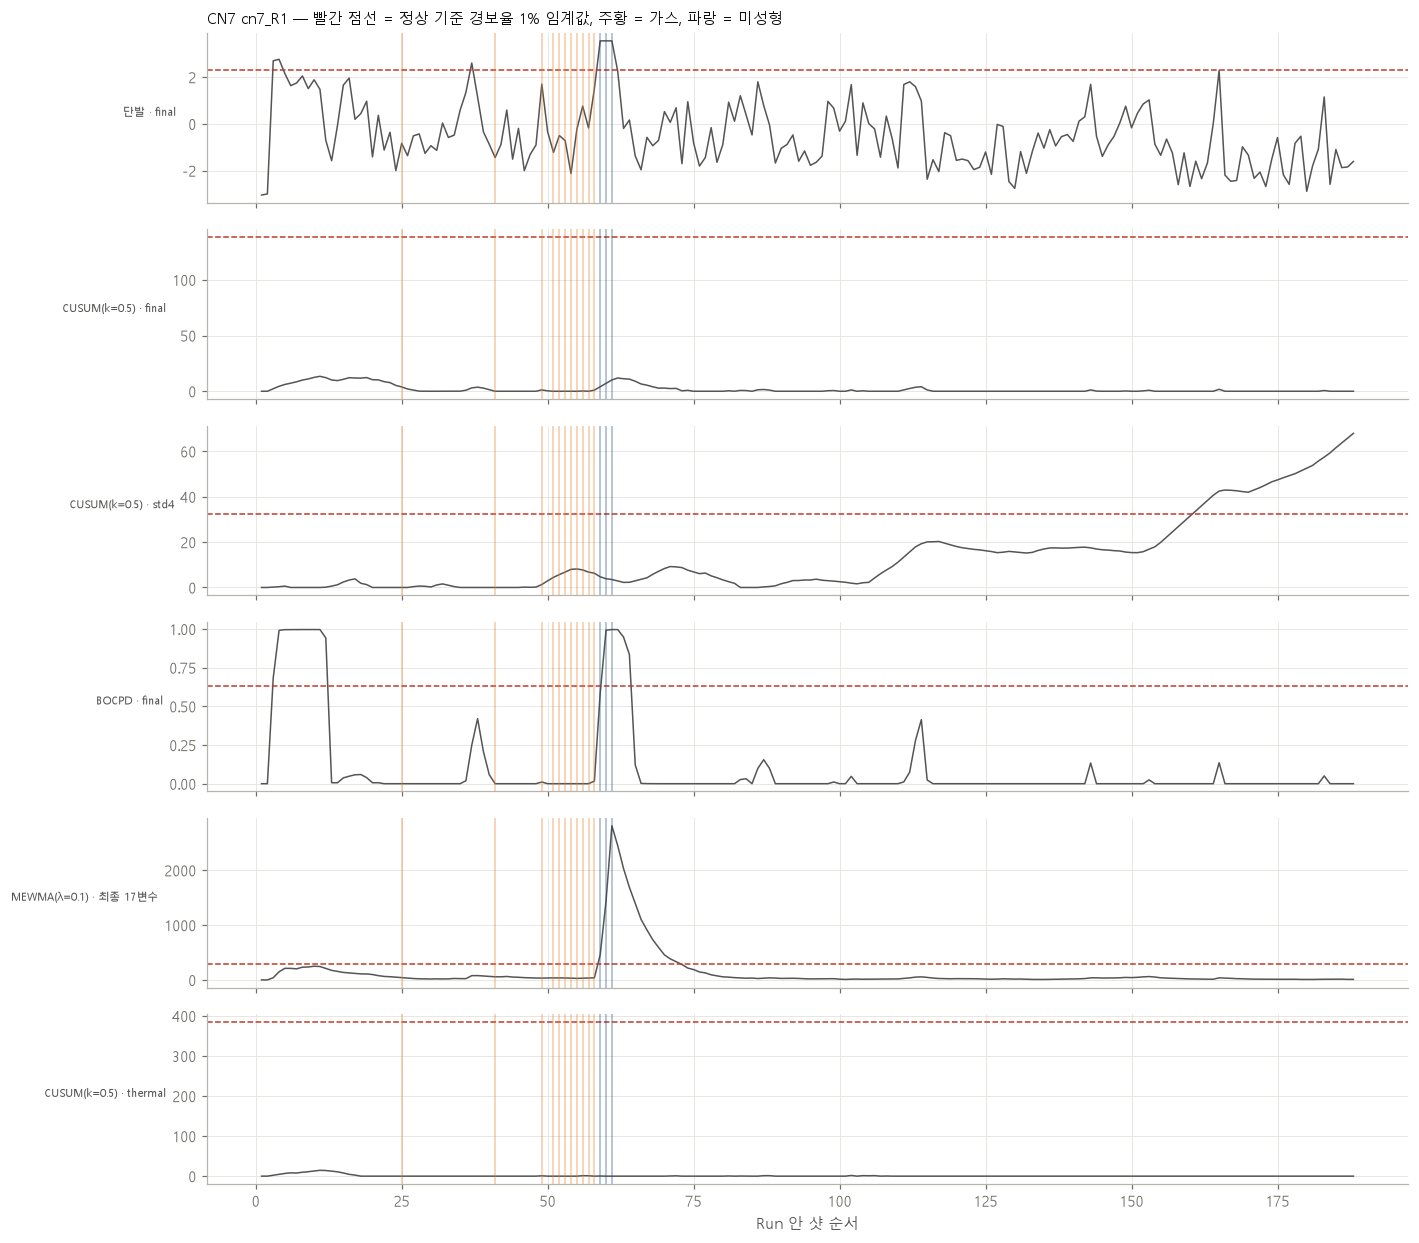

In [7]:
CP.plot_run(R, 'cn7', rate=0.01)

## RG3 — 경보율 3%

In [8]:
display(CP.best_table(R, 'rg3', rate=0.03).round(3))
display(CP.best_table(R, 'rg3', rate=0.10).head(8).round(3))

,방법,경보(검사) 샷,TP,불량,가스,미성형,Precision,Recall,F1,정규화 Precision,불량 없는 Run 경보율,p_불량,p_가스,p_미성형,[같은 K] 최종 모델 점수 상위 K 불량,[같은 K] 최종 모델 점수 상위 K 가스,[같은 K] 최종 모델 점수 상위 K 미성형,[같은 K] 경보 먼저 + std4 상위 K 불량,[같은 K] 경보 먼저 + std4 상위 K 가스,[같은 K] 경보 먼저 + std4 상위 K 미성형
0,BOCPD · std4,65,4,4/25,3/17,1/8,0.062,0.16,0.089,0.16,0.220,0.264,0.276,0.57,2/25,1/17,1/8,2/25,1/17,1/8
1,단발 · std4,33,2,2/25,1/17,1/8,0.061,0.08,0.069,0.08,0.024,0.418,0.678,0.32,1/25,1/17,0/8,2/25,1/17,1/8
2,단발 · final,28,1,1/25,1/17,0/8,0.036,0.04,0.038,0.04,0.098,0.672,0.525,NaN,1/25,1/17,0/8,2/25,1/17,1/8
3,단발 · thermal,39,1,1/25,1/17,0/8,0.026,0.04,0.031,0.04,0.146,0.790,0.666,NaN,1/25,1/17,0/8,2/25,1/17,1/8
4,BOCPD · final,43,1,1/25,1/17,0/8,0.023,0.04,0.029,0.04,0.220,0.874,0.792,NaN,1/25,1/17,0/8,2/25,1/17,1/8
5,EWMA(λ=0.2) · final,14,0,0/25,0/17,0/8,0.000,0.00,0.000,0.00,0.024,NaN,NaN,NaN,0/25,0/17,0/8,1/25,1/17,0/8
6,CUSUM(k=0.5) · std4,0,0,0/25,0/17,0/8,0.000,0.00,0.000,NaN,0.000,NaN,NaN,NaN,0/25,0/17,0/8,0/25,0/17,0/8
7,CUSUM(k=1.0) · final,29,0,0/25,0/17,0/8,0.000,0.00,0.000,0.00,0.195,NaN,NaN,NaN,1/25,1/17,0/8,2/25,1/17,1/8
8,CUSUM(k=0.5) · final,0,0,0/25,0/17,0/8,0.000,0.00,0.000,NaN,0.000,NaN,NaN,NaN,0/25,0/17,0/8,0/25,0/17,0/8
9,EWMA(λ=0.2) · std4,13,0,0/25,0/17,0/8,0.000,0.00,0.000,0.00,0.000,NaN,NaN,NaN,0/25,0/17,0/8,1/25,1/17,0/8


,방법,경보(검사) 샷,TP,불량,가스,미성형,Precision,Recall,F1,정규화 Precision,불량 없는 Run 경보율,p_불량,p_가스,p_미성형,[같은 K] 최종 모델 점수 상위 K 불량,[같은 K] 최종 모델 점수 상위 K 가스,[같은 K] 최종 모델 점수 상위 K 미성형,[같은 K] 경보 먼저 + std4 상위 K 불량,[같은 K] 경보 먼저 + std4 상위 K 가스,[같은 K] 경보 먼저 + std4 상위 K 미성형
0,BOCPD · std4,123,8,8/25,3/17,5/8,0.065,0.32,0.108,0.32,0.244,0.119,0.752,0.011,4/25,2/17,2/8,6/25,4/17,2/8
1,단발 · thermal,68,4,4/25,2/17,2/8,0.059,0.16,0.086,0.16,0.293,0.235,0.567,0.171,2/25,1/17,1/8,3/25,1/17,2/8
2,EWMA(λ=0.2) · std4,43,4,4/25,1/17,3/8,0.093,0.16,0.118,0.16,0.000,0.121,0.792,0.025,1/25,1/17,0/8,2/25,1/17,1/8
3,BOCPD · thermal,75,4,4/25,3/17,1/8,0.053,0.16,0.080,0.16,0.244,0.348,0.361,0.595,2/25,1/17,1/8,3/25,1/17,2/8
4,단발 · std4,66,3,3/25,1/17,2/8,0.045,0.12,0.066,0.12,0.122,0.525,0.876,0.200,2/25,1/17,1/8,3/25,1/17,2/8
5,단발 · final,62,2,2/25,1/17,1/8,0.032,0.08,0.046,0.08,0.195,0.718,0.825,0.549,2/25,1/17,1/8,2/25,1/17,1/8
6,MEWMA(λ=0.3) · 최종 17변수,62,2,2/25,0/17,2/8,0.032,0.08,0.046,0.08,0.220,0.722,NaN,0.143,2/25,1/17,1/8,2/25,1/17,1/8
7,BOCPD · final,72,2,2/25,1/17,1/8,0.028,0.08,0.041,0.08,0.244,0.795,0.905,0.535,2/25,1/17,1/8,3/25,1/17,2/8


,제품,Run,방법,경보율,Run 평가 샷,Run 불량,첫 불량 seq,첫 미성형 seq,첫 경보 seq,Run 안 경보 수,미성형 직전 50샷 경보 수,미성형보다 몇 샷 먼저 경보,첫 불량보다 몇 샷 먼저 경보
34,rg3,rg3_R2,단발 · final,0.01,103,5,28,45,3.0,4,4,42,25.0
35,rg3,rg3_R2,CUSUM(k=0.5) · final,0.01,103,5,28,45,NaN,0,0,0,NaN
36,rg3,rg3_R2,CUSUM(k=1.0) · final,0.01,103,5,28,45,5.0,12,12,40,23.0
37,rg3,rg3_R2,EWMA(λ=0.2) · final,0.01,103,5,28,45,6.0,4,4,39,22.0
38,rg3,rg3_R2,BOCPD · final,0.01,103,5,28,45,3.0,10,10,42,25.0
39,rg3,rg3_R2,단발 · std4,0.01,103,5,28,45,3.0,6,6,42,25.0
40,rg3,rg3_R2,CUSUM(k=0.5) · std4,0.01,103,5,28,45,NaN,0,0,0,NaN
41,rg3,rg3_R2,CUSUM(k=1.0) · std4,0.01,103,5,28,45,NaN,0,0,0,NaN
42,rg3,rg3_R2,EWMA(λ=0.2) · std4,0.01,103,5,28,45,8.0,4,4,37,20.0
43,rg3,rg3_R2,BOCPD · std4,0.01,103,5,28,45,4.0,12,12,41,24.0


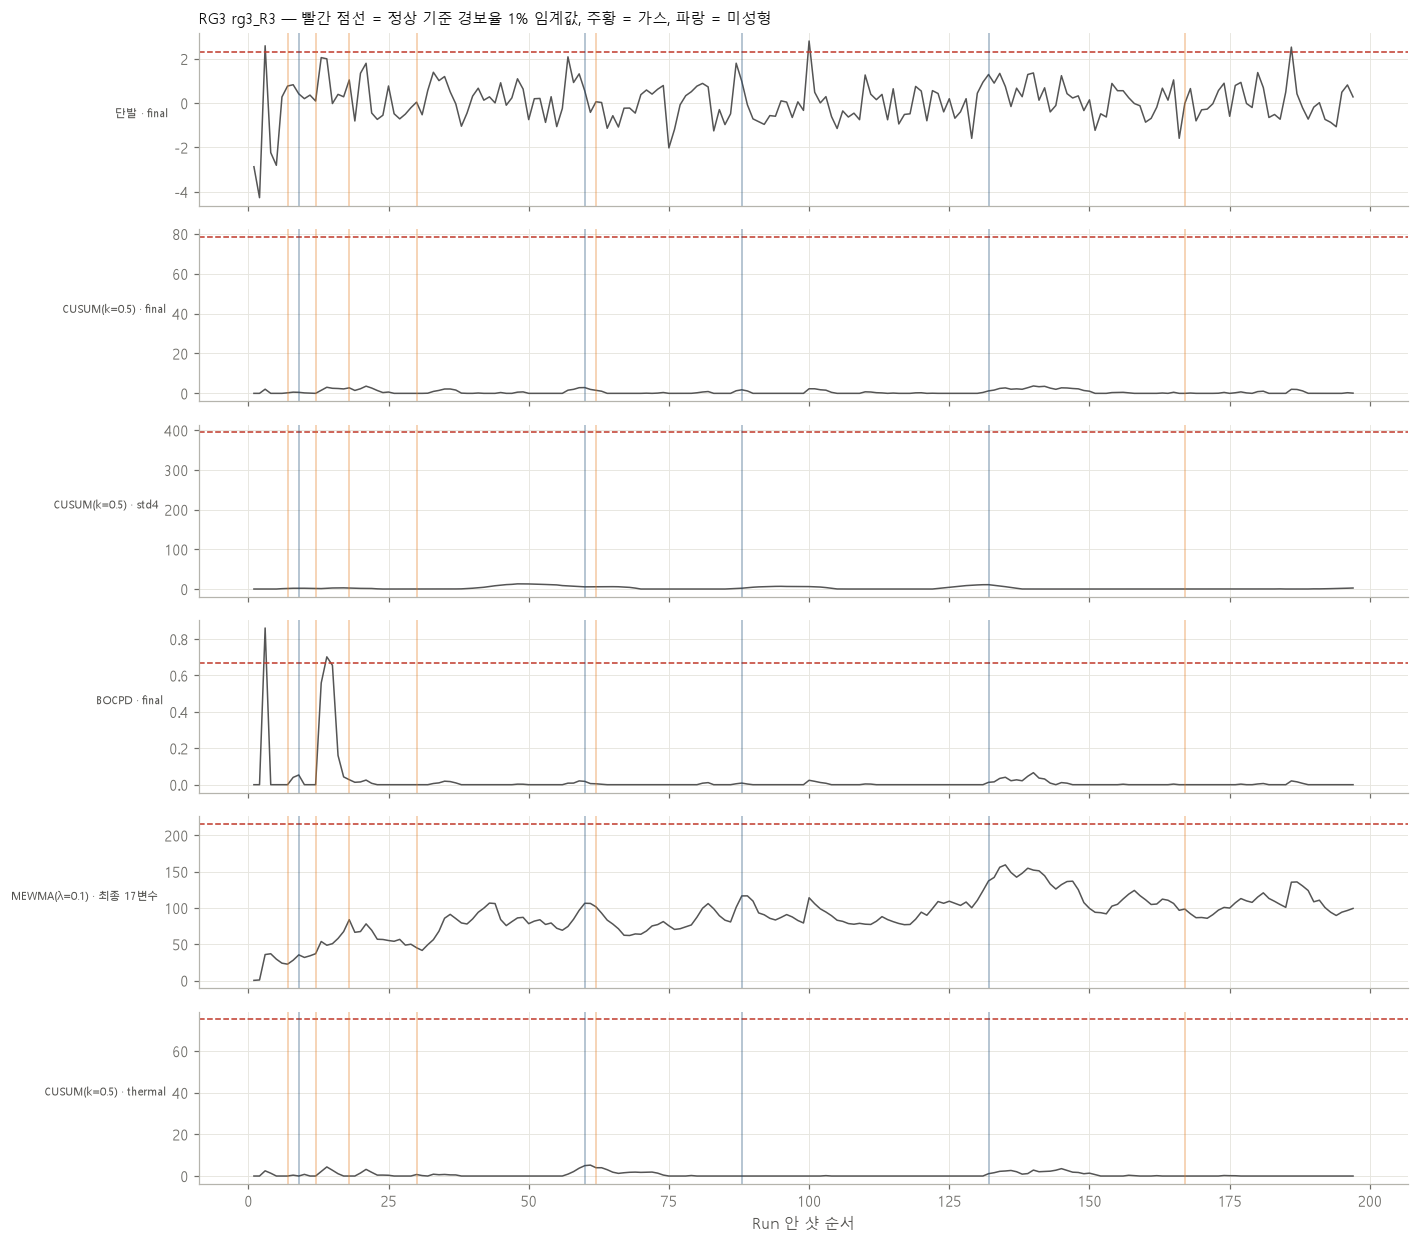

In [9]:
display(E[E['제품'] == 'rg3'].round(2))
CP.plot_run(R, 'rg3', rate=0.01)

## 읽는 법 · 판단 기준
1. **같은 K 비교**: 순차 감시의 `불량`·`가스`가 `[같은 K] 최종 모델 점수`·`[같은 K] 경보 먼저 + std4`보다 많아야 새 기법의 이득
2. **p_가스 / p_미성형 < 0.05**: 몰림 구조를 유지한 우연보다 많이 잡음 (방법이 17개×경보율 4개라 여러 번 본 것 → 0.05 근처는 약한 근거)
3. **불량 없는 Run 경보율 ≈ 목표 경보율**: 크게 높으면 labeled 기간이 정상 기준과 달라 경보가 남발된다는 뜻
4. **에피소드 표**: 미성형 전에 경보가 이어졌다면 '선제 경보' 사례로 보고서 4장에 사용 (단, 에피소드 1개 → 사례로만)